# Resultados: Montecarlo, red neuronal y fórmula cerrada

Este notebook reúne los resultados oficiales del reto. Compara tres formas de valorar la call asiática sobre WMT, MRK y NVDA:

- **Montecarlo (MC):** la referencia. Su prima es la media de los payoffs de T20, descontada con e^(−0,01 × (5 − t)).
- **Red neuronal (GRU y LSTM):** lee las trayectorias completas y predice el payoff de T20. Se evalúa con las **10.000 simulaciones de test**, que no vio en el train, y se compara con el MC **sobre esas mismas simulaciones**. Su error se mide siempre frente al MC.
- **Fórmula cerrada:** calcula el payoff de manera diferente (una sola media geométrica de los 60 precios, menos 1), así que sus primas son mucho más pequeñas. Se incluye como referencia, tal como se planteó en clase, y no se calcula su error.

El MC y la red calculan el payoff de T20 y lo llevan hacia atrás con el descuento. La fórmula va hacia delante: en cada trimestre t usa solo los t primeros trimestres de cada simulación y calcula cuánto vale en ese momento el pago esperado de lo que falta. En T20 no queda nada por valorar y su valor es el pago real. Las tres primas se pueden poner en el mismo gráfico.

**Contenido**

1. Datos y parámetros
2. Fórmula cerrada
3. Montecarlo frente a la fórmula, con las 100.000 simulaciones
4. Test (10.000 simulaciones): red, Montecarlo y fórmula
   - 4.1 Predicciones de la red
   - 4.2 Payoff de T20
   - 4.3 Prima en t0
   - 4.4 Prima en todos los trimestres
5. Conclusiones


---
# 1. Datos y parámetros

Las trayectorias vienen de `montecarlo.ipynb`. El **test** son las mismas 10.000 simulaciones que usa `rnn.ipynb` (reparto 80 / 10 / 10 con la semilla 0), así que la red no las vio en el train.

In [1]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"   # PyTorch y matplotlib traen cada uno su OpenMP en Windows

import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

AZUL, ROJO, GRIS = "#001391", "#FF4B4B", "#8A8D91"   # paleta del proyecto

MU, T, N_TRIM, M = 0.01, 5, 20, 3        # tasa libre de riesgo, años, trimestres y acciones
DT = T / N_TRIM                          # un trimestre, en años
SIGMA = np.array([0.21915220410541955, 0.23593283496457446, 0.5174176492623017])   # volatilidad anual: WMT, MRK, NVDA
RHO = np.array([[1.0,                 0.23448266076590554, 0.2254536587614545 ],
                [0.23448266076590554, 1.0,                 0.12948744681423088],
                [0.2254536587614545,  0.12948744681423088, 1.0                ]])

datos = np.load("Datos/resultados_montecarlo.npz")
X, payoff = datos["x"], datos["payoff"]       # precios S_1..S_20 con S_0 = 1: (100000, 20, 3) | payoff de T20: (100000,)
logX = np.log(X)

# Test: las mismas 10.000 simulaciones de rnn.ipynb
idx = torch.randperm(len(X), generator=torch.Generator().manual_seed(0)).numpy()
idx_test = idx[int(0.9 * len(X)):]

# Factor que lleva un payoff de T20 al trimestre k: e^(-mu (T - t_k)), con t_k = k * DT, k = 0..20
ks = np.arange(N_TRIM + 1)
factor = np.exp(-MU * (T - ks * DT))

G = np.exp(logX.mean(axis=1))                 # media geométrica de cada acción: (100000, 3)
print("X:", X.shape, "| test:", len(idx_test), "simulaciones")
print("El payoff guardado coincide con max(suma de las 3 medias geométricas - 3, 0):", np.allclose(np.maximum(G.sum(axis=1) - 3, 0), payoff, atol=1e-5))
print(f"Prima MC con 100.000: {factor[0] * payoff.mean():.4f} | con las 10.000 de test: {factor[0] * payoff[idx_test].mean():.4f}")

X: (100000, 20, 3) | test: 10000 simulaciones
El payoff guardado coincide con max(suma de las 3 medias geométricas - 3, 0): True
Prima MC con 100.000: 0.3014 | con las 10.000 de test: 0.2971


---
# 2. Fórmula cerrada

La fórmula cerrada (`BasketGeomAsian`) calcula el payoff de la **media geométrica conjunta de la cesta** (los 60 precios) menos 1, que es el que tiene fórmula exacta. El nuestro suma las tres medias geométricas, una por acción, y por eso las primas de la fórmula salen entre 3,7 y 4 veces más pequeñas (se detalla en 3.1). No se cambia nada de la fórmula, y se usa como referencia.

Las funciones `Black` y `BasketGeomAsian` se leen directamente del notebook que nos dieron los profesores (`MonteCarlo_y_Formula_cerrada_25_26.ipynb`), sin copiarlas. Dado un instante v con v trimestres observados, la fórmula devuelve la prima en ese momento a partir de la historia de una simulación. Llamarla 100.000 × 21 veces sería muy lento, así que se usa la versión vectorizada de `formula_cerrada.ipynb`, que calcula todas las simulaciones de golpe. Aquí se amplía a v = 20, donde no queda tiempo y la prima es el pago real.


In [2]:
import json
import re

def cargar_funciones_bbva(ruta="MonteCarlo_y_Formula_cerrada_25_26.ipynb"):
    """Ejecuta las celdas del notebook de los profesores que definen Black y BasketGeomAsian, sin copiarlas."""
    espacio = {"np": np}
    for celda in json.load(open(ruta, encoding="utf-8"))["cells"]:
        fuente = "".join(celda["source"])
        if celda["cell_type"] == "code" and re.search(r"def (Black|BasketGeomAsian)\b", fuente):
            exec(fuente, espacio)
    return espacio["Black"], espacio["BasketGeomAsian"]


Black, BasketGeomAsian = cargar_funciones_bbva()      # funciones originales de los profesores


def bbva_vectorizada(v):
    """Prima de la fórmula cerrada con v trimestres observados (v = 0..20) para TODAS las simulaciones a la vez."""
    suma_obs = logX[:, :v, :].sum(axis=(1, 2))                       # suma de los log-precios observados
    if v == N_TRIM:                                                  # sin tiempo por valorar: queda el pago real
        return np.maximum(np.exp(suma_obs / (M * N_TRIM)) - 1.0, 0)
    tiempos = np.linspace(0, T, N_TRIM + 1)
    pendientes = tiempos[v + 1:] - tiempos[v]                        # tiempos que faltan hasta cada fecha
    mu_v = np.sum(MU - 0.5 * SIGMA**2) * pendientes.sum() / (M * N_TRIM)
    cov = np.diag(SIGMA) @ RHO @ np.diag(SIGMA)
    xx, yy = np.meshgrid(pendientes, pendientes, sparse=True)
    V = cov.sum() * np.minimum(xx, yy).sum() / (M * M * N_TRIM * N_TRIM)
    ultimo = logX[:, v - 1, :].sum(axis=1) if v > 0 else 0.0         # log del último precio observado
    forward = np.exp(suma_obs / (M * N_TRIM) + (N_TRIM - v) / (M * N_TRIM) * ultimo + mu_v + 0.5 * V)
    restante = T - tiempos[v]
    return Black(forward, 1.0, restante, MU, np.sqrt(V / restante), True)

**Comprobación.** Se compara la versión vectorizada con la función original de los profesores en 5 simulaciones al azar y en los 21 instantes (v = 0..20). La diferencia debe ser prácticamente cero.

In [3]:
rng = np.random.default_rng(0)
muestra = rng.choice(len(X), size=5, replace=False)
dif_max = 0.0
with np.errstate(divide="ignore", invalid="ignore"):                 # en v = 20 la original divide 0 / 0, aunque no usa ese valor
    for v in range(N_TRIM + 1):
        vec = bbva_vectorizada(v)
        for h in muestra:
            historia = np.concatenate([np.ones((M, 1)), X[h, :v, :].T], axis=1)            # [S_0, S_1, ..., S_v]: (3, v + 1)
            original = BasketGeomAsian(N_TRIM + 1, v, MU, M, SIGMA, RHO, T, historia, True)
            dif_max = max(dif_max, abs(original - vec[h]))
print("Diferencia máxima entre la función original y la vectorizada:", dif_max)

inicio = time.time()
prima_bbva = np.column_stack([bbva_vectorizada(v) for v in range(N_TRIM + 1)])     # (simulaciones, instantes v = 0..20)
print("prima_bbva:", prima_bbva.shape, "| tiempo:", round(time.time() - inicio, 2), "s")

Diferencia máxima entre la función original y la vectorizada: 4.440892098500626e-16
prima_bbva: (100000, 21) | tiempo: 0.41 s


---
# 3. Montecarlo frente a la fórmula, con las 100.000 simulaciones

Con todas las trayectorias, la prima de cada trimestre t es la media de las 100.000 simulaciones:

- **Montecarlo:** media del payoff de T20, llevada al trimestre t con el descuento e^(−0,01 × (5 − t)).
- **Fórmula cerrada:** media de la prima de la fórmula calculada en cada simulación con los t primeros trimestres.

La fórmula calcula el payoff de manera diferente, por eso sus valores son mucho más pequeños. Se deja como referencia.


In [4]:
tabla_mc = pd.DataFrame({
    "Montecarlo": factor * payoff.mean(),
    "Fórmula cerrada": prima_bbva.mean(axis=0),
}, index=pd.Index(ks, name="t"))
tabla_mc.round(4)

,Montecarlo,Fórmula cerrada
t,,
0,0.3014,0.0760
1,0.3021,0.1510
2,0.3029,0.0897
3,0.3036,0.1286
4,0.3044,0.0887
5,0.3052,0.0818
6,0.3059,0.0818
7,0.3067,0.0823
8,0.3075,0.0825


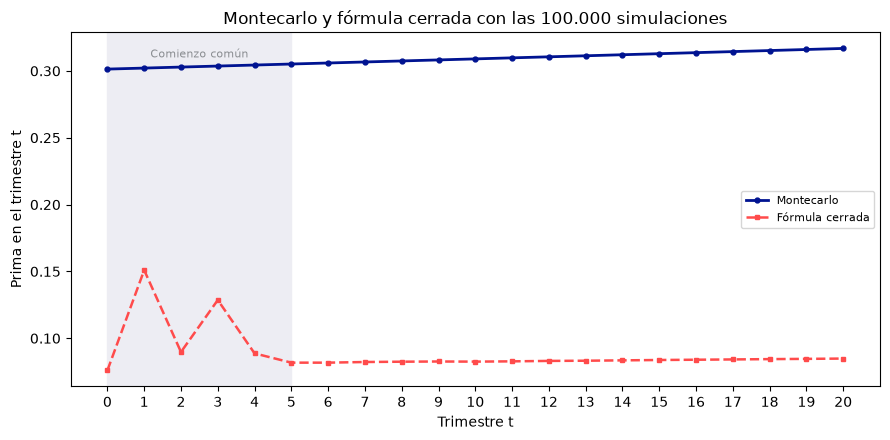

In [5]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.axvspan(0, 5, color="#EDEDF3", zorder=0)
ax.text(2.5, tabla_mc["Montecarlo"].max(), "Comienzo común", ha="center", va="top", fontsize=8, color=GRIS)
ax.plot(ks, tabla_mc["Montecarlo"], color=AZUL, lw=2, marker="o", ms=3.5, label="Montecarlo")
ax.plot(ks, tabla_mc["Fórmula cerrada"], color=ROJO, lw=1.8, ls="--", marker="s", ms=3.5, label="Fórmula cerrada")
ax.set(xlabel="Trimestre t", ylabel="Prima en el trimestre t", title="Montecarlo y fórmula cerrada con las 100.000 simulaciones")
ax.set_xticks(ks); ax.legend(fontsize=8, loc="center right")
plt.tight_layout(); plt.show()

**Cómo leer el gráfico.** Cada punto es la prima media de las 100.000 simulaciones en un trimestre. El Montecarlo (azul) sube despacio de 0,3014 a 0,3168 por el descuento. La fórmula cerrada (rojo) queda entre 0,076 y 0,151: salta en los trimestres 1 a 4 y se estabiliza desde el 5. La zona gris son esos cinco primeros trimestres, iguales en todas las simulaciones.


#### 3.1 Conclusiones de la comparación con la fórmula

- **Las dos primas suben con el tiempo por el descuento.** El Montecarlo pasa de 0,3014 en t = 0 a 0,3168 en t = 20, y la fórmula de 0,0760 a 0,0848. Desde t = 5 el aumento es de un 3,8 % en el Montecarlo y de un 3,7 % en la fórmula, que es lo que se descuenta menos entre t = 5 y t = 20.
- **La prima del reto es unas 3,7 veces la de la fórmula** (3,97 en t = 0 y entre 3,73 y 3,74 desde t = 5), porque calculan el payoff de manera diferente. El nuestro suma las tres medias geométricas y la fórmula cerrada calcula una sola media geométrica de la cesta. La fórmula se queda como referencia.
- **La fórmula salta en los trimestres 1 a 4** (0,151, 0,090, 0,129 y 0,089). Los cinco primeros trimestres son comunes a todas las simulaciones, así que en cada uno la fórmula valora esa historia concreta y no un promedio. Por eso están sombreados como "comienzo común".

---
# 4. Test: red, Montecarlo y fórmula cerrada

Desde aquí todo se calcula con las 10.000 simulaciones de test. Las redes no las vieron en el train, y el Montecarlo y la fórmula cerrada se calculan sobre esas mismas trayectorias, así que las tres primas se pueden comparar.

## 4.1 Predicciones de la red

Aquí usamos las redes que ya entrenamos en `rnn.ipynb`. No se entrena nada de nuevo. La celda hace tres cosas:

1. **Prepara la red.** Define la misma red que entrenamos: una LSTM y una GRU que leen una trayectoria de 20 trimestres y devuelven un solo número, el payoff de T20. La LSTM tiene 2 capas de 32 neuronas y la GRU, 2 capas de 64.
2. **Carga las redes guardadas y las usa.** Hay 6 redes: la LSTM y la GRU, cada una con 3 semillas (0, 1 y 2). A cada una se le dan las 10.000 simulaciones de test, que no vio al entrenar, y se guarda el payoff que predice para cada simulación.
3. **Comprueba que todo cuadra.** Compara lo que predice cada red con el payoff real del Montecarlo y muestra su error medio en test, como media de las 3 semillas. Si sale lo mismo que en `rnn.ipynb` (MAE de 0,00172 en la LSTM y de 0,00080 en la GRU), estamos usando los mismos modelos y el mismo reparto de test.

In [6]:
TIPOS = {"LSTM": nn.LSTM, "GRU": nn.GRU}
CONFIG = {"LSTM": dict(capas=2, dropout=0.0, neuronas=32), "GRU": dict(capas=2, dropout=0.0, neuronas=64)}   # ganadoras de la ronda 2
SEMILLAS = [0, 1, 2]


class RedRecurrente(nn.Module):
    def __init__(self, tipo, capas=1, dropout=0.0, neuronas=32):
        super().__init__()
        self.rnn = TIPOS[tipo](input_size=3, hidden_size=neuronas, num_layers=capas, dropout=dropout, batch_first=True)
        self.salida = nn.Linear(neuronas, 1)

    def forward(self, x):
        h, _ = self.rnn(x)                  # (batch, 20 trimestres, neuronas)
        return self.salida(h[:, -1, :])     # estado del último trimestre


x_test = torch.tensor(logX[idx_test], dtype=torch.float32)       # entrada de la red: log(X) de test
real = payoff[idx_test]                                          # payoff real (Montecarlo) de las 10.000 simulaciones

preds, segundos = {}, {}
for tipo in CONFIG:
    for s in SEMILLAS:
        red = RedRecurrente(tipo, **CONFIG[tipo])
        red.load_state_dict(torch.load(f"modelos/r2_final_{tipo.lower()}" + (f"_s{s}" if s else "") + ".pt"))
        red.eval()
        inicio = time.time()
        with torch.no_grad():
            preds[(tipo, s)] = red(x_test).squeeze(-1).numpy()
        segundos[(tipo, s)] = time.time() - inicio

comprobacion = pd.DataFrame({
    "MAE test (media)": {t: np.mean([np.abs(preds[(t, s)] - real).mean() for s in SEMILLAS]) for t in CONFIG},
    "MAE desviación entre semillas": {t: np.std([np.abs(preds[(t, s)] - real).mean() for s in SEMILLAS], ddof=1) for t in CONFIG},
    "RMSE test (media)": {t: np.mean([np.sqrt(((preds[(t, s)] - real) ** 2).mean()) for s in SEMILLAS]) for t in CONFIG},
})
comprobacion.round(5)

,MAE test (media),MAE desviación entre semillas,RMSE test (media)
LSTM,0.00172,0.00038,0.00299
GRU,0.00080,0.00001,0.00156


## 4.2 Payoff de T20: red frente a Montecarlo

Cada punto es una simulación de test. En el eje horizontal está el payoff real (Montecarlo) y en el vertical, el que predice la red con la trayectoria completa (semilla 0). Si la red acertara siempre, todos los puntos estarían sobre la diagonal.

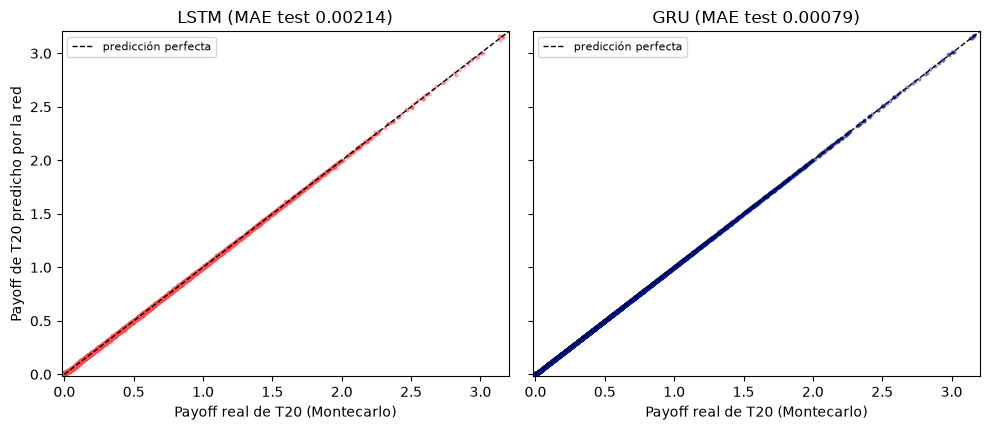

In [7]:
fig, ejes = plt.subplots(1, 2, figsize=(10, 4.4), sharex=True, sharey=True)
lim = np.percentile(real, 99.9)
for eje, tipo, color in zip(ejes, ["LSTM", "GRU"], [ROJO, AZUL]):
    eje.scatter(real, preds[(tipo, 0)], s=4, alpha=0.35, color=color)
    eje.plot([0, lim], [0, lim], color="black", lw=1, ls="--", label="predicción perfecta")
    mae = np.abs(preds[(tipo, 0)] - real).mean()
    eje.set(title=f"{tipo} (MAE test {mae:.5f})", xlabel="Payoff real de T20 (Montecarlo)", xlim=(-0.02, lim), ylim=(-0.02, lim))
    eje.legend(loc="upper left", fontsize=8)
ejes[0].set_ylabel("Payoff de T20 predicho por la red")
plt.tight_layout(); plt.show()

**Cómo leer el gráfico.** Los puntos de las dos redes quedan pegados a la diagonal, desde payoffs cercanos a 0 hasta más de 3, con un MAE de test de 0,00214 en la LSTM y de 0,00079 en la GRU para esta semilla. Los ejes se cortan en el percentil 99,9 de los payoffs reales, y a esta escala no se ven errores de unas milésimas, por eso se añade el gráfico siguiente.


La segunda mirada es el **error** de la red en cada simulación. En el eje horizontal sigue estando el payoff real de T20 (Montecarlo). En el vertical ya no se pone lo que predice la red, sino cuánto se equivoca: predicho menos real. Un punto en 0 es un acierto exacto, un punto por encima es que la red se pasa y un punto por debajo es que se queda corta. Los dos paneles comparten escala, así que se puede ver a simple vista qué red se equivoca más y si lo hace más en los payoffs bajos o en los altos.

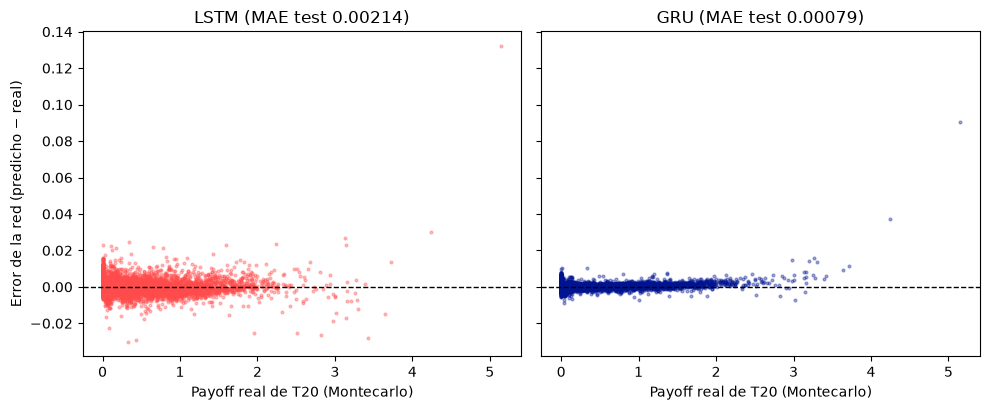

In [8]:
fig, ejes = plt.subplots(1, 2, figsize=(10, 4.2), sharex=True, sharey=True)
for eje, tipo, color in zip(ejes, ["LSTM", "GRU"], [ROJO, AZUL]):
    error = preds[(tipo, 0)] - real
    eje.scatter(real, error, s=4, alpha=0.35, color=color)
    eje.axhline(0, color="black", lw=1, ls="--")
    eje.set(title=f"{tipo} (MAE test {np.abs(error).mean():.5f})",
            xlabel="Payoff real de T20 (Montecarlo)")
ejes[0].set_ylabel("Error de la red (predicho − real)")
plt.tight_layout(); plt.show()

**Cómo leer el gráfico.** La nube de la LSTM es más ancha que la de la GRU, de acuerdo con su MAE más alto: la mayoría de sus errores quedan entre −0,02 y 0,02, y los de la GRU entre −0,01 y 0,01. Los errores mayores están en unas pocas simulaciones con payoff por encima de 4, donde las dos redes sobrestiman (con un payoff cercano a 5, hasta +0,13 la LSTM y +0,09 la GRU).


## 4.3 Prima en t0: red frente a Montecarlo

La prima en t0 es el payoff medio de T20 descontado hasta t0 (multiplicado por e^(−0,01·5) = 0,9512). Se calcula así para Montecarlo y para las redes.

**Qué se compara**
- **Montecarlo con 100.000 simulaciones**, con su intervalo de confianza al 95 %.
- **Montecarlo con las 10.000 simulaciones de test**, que es la referencia justa para las redes, porque son las mismas trayectorias que ven ellas.
- **LSTM y GRU**, con la prima como media de las tres semillas.
- **Fórmula cerrada**, como referencia (con su prima en t0).

**Tiempo**
- Se mide cuánto tarda en valorar las 10.000 trayectorias de test, en un solo lote, cada red y el cálculo directo del payoff.

In [9]:
prima_mc100 = factor[0] * payoff.mean()
error_mc100 = factor[0] * payoff.std(ddof=1) / np.sqrt(len(payoff))
prima_test = factor[0] * real.mean()

inicio = time.time()
payoff_directo = np.maximum(np.exp(logX[idx_test].mean(axis=1)).sum(axis=1) - 3, 0)     # payoff calculado directamente
seg_mc = time.time() - inicio

filas = [{"método": "Montecarlo, 100.000 simulaciones", "prima": prima_mc100},
         {"método": "Montecarlo, 10.000 de test", "prima": prima_test, "segundos": seg_mc}]
for t in CONFIG:
    primas = np.array([factor[0] * preds[(t, s)].mean() for s in SEMILLAS])
    filas.append({"método": f"{t}, media de {len(SEMILLAS)} semillas", "prima": primas.mean(), "desviación": primas.std(ddof=1),
                  "diferencia": primas.mean() - prima_test, "diferencia %": 100 * (primas.mean() / prima_test - 1),
                  "segundos": np.mean([segundos[(t, s)] for s in SEMILLAS])})
filas.append({"método": "Fórmula cerrada", "prima": prima_bbva[idx_test, 0].mean()})

tabla_prima = pd.DataFrame(filas).set_index("método")
print(f"Montecarlo con 100.000: {prima_mc100:.4f} ± {1.96 * error_mc100:.4f} (intervalo de confianza al 95 %)")
print("El Montecarlo de 100.000 es la mejor estimación del precio. El de 10.000 de test es el que se usa para medir el error de las redes, porque son las mismas trayectorias que ellas valoran.")
tabla_prima.round(5)

Montecarlo con 100.000: 0.3014 ± 0.0029 (intervalo de confianza al 95 %)
El Montecarlo de 100.000 es la mejor estimación del precio. El de 10.000 de test es el que se usa para medir el error de las redes, porque son las mismas trayectorias que ellas valoran.


,prima,segundos,desviación,diferencia,diferencia %
método,,,,,
"Montecarlo, 100.000 simulaciones",0.30137,NaN,NaN,NaN,NaN
"Montecarlo, 10.000 de test",0.29714,0.00847,NaN,NaN,NaN
"LSTM, media de 3 semillas",0.29754,0.09733,0.00031,0.00040,0.13517
"GRU, media de 3 semillas",0.29729,0.31032,0.00010,0.00016,0.05258
Fórmula cerrada,0.07598,NaN,NaN,NaN,NaN


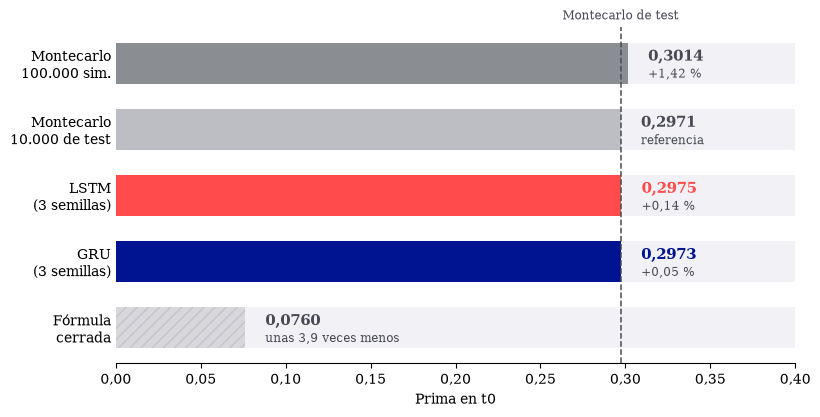

In [10]:
ROJO, AZUL, GRIS, OSC = "#FF4B4B", "#001391", "#8A8D91", "#4A4A55"      # paleta del proyecto
coma = lambda v, d=4: f"{v:.{d}f}".replace(".", ",")
p, d = tabla_prima["prima"].values, tabla_prima["diferencia %"].values
mc = p[1]                                                               # referencia: Montecarlo de test
filas = [("Montecarlo\n100.000 sim.", p[0], GRIS, 1.0, f"{100 * (p[0] / mc - 1):+.2f} %"),
         ("Montecarlo\n10.000 de test", p[1], GRIS, 0.5, "referencia"),
         ("LSTM\n(3 semillas)", p[2], ROJO, 1.0, f"{d[2]:+.2f} %"),
         ("GRU\n(3 semillas)", p[3], AZUL, 1.0, f"{d[3]:+.2f} %"),
         ("Fórmula\ncerrada", p[4], GRIS, 0.25, f"unas {mc / p[4]:.1f} veces menos")]

with plt.rc_context({"font.family": "serif", "font.serif": ["Latin Modern Roman", "DejaVu Serif"], "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False}):
    fig, ax = plt.subplots(figsize=(8.6, 4.2))
    y = np.arange(len(filas))
    ax.barh(y, 0.40, height=0.62, color="#F1F1F6", zorder=1)                       # pista de fondo
    for yi, (nom, v, c, a, txt) in zip(y, filas):
        cerrada = "cerrada" in nom
        ax.barh(yi, v, height=0.62, color=c, alpha=a, zorder=3, lw=0,
                hatch="///" if cerrada else None, edgecolor=GRIS if cerrada else c)
        ax.text(v + 0.012, yi - 0.1, coma(v), va="center", fontweight="bold", fontsize=11,
                color=OSC if c == GRIS else c, zorder=5)
        ax.text(v + 0.012, yi + 0.17, txt.replace(".", ","), va="center", fontsize=8.5, color=OSC, zorder=5)
    ax.axvline(mc, color=OSC, ls="--", lw=1.1, zorder=4)
    ax.text(mc, -0.62, "Montecarlo de test", ha="center", va="bottom", fontsize=8.5, color=OSC)
    ax.set_yticks(y, [f[0] for f in filas]); ax.invert_yaxis()
    ax.set(xlim=(0, 0.40), xlabel="Prima en t0"); ax.tick_params(axis="y", length=0)
    ax.xaxis.set_major_formatter(lambda v, _: coma(v, 2))
    fig.subplots_adjust(left=0.19, right=0.98, bottom=0.13, top=0.93)
    plt.show()

**Cómo leer el gráfico.** Cada barra es una prima en t0 y la franja gris de fondo marca el máximo del eje. La línea discontinua es el Montecarlo de test, la referencia de las redes, y el porcentaje bajo cada valor es su diferencia con ese Montecarlo. La LSTM (+0,14 %) y la GRU (+0,05 %) llegan a la línea. El Montecarlo de 100.000 queda un 1,42 % por encima, porque incluye esas 10.000 simulaciones y otras 90.000 más. La fórmula cerrada queda unas 3,9 veces por debajo. Las cuatro primas parecidas casi no se distinguen en las barras, y la diferencia se lee en los números y en los porcentajes.


## 4.4 Prima en todos los trimestres

La red y el MC dan el payoff de T20 y se **llevan hacia atrás** al trimestre t con e^(−0,01 × (5 − t)). La fórmula cerrada va **hacia delante**: en cada t usa los t primeros trimestres de cada simulación de test y se promedia. En t = 20 todo es el pago real de su contrato.

Como la red y el MC solo cambian en el descuento, su diferencia relativa es la misma en todos los trimestres. Por eso el gráfico lleva un segundo panel con la diferencia **red − MC**, para que se vea el error. En la tabla, la diferencia de la red se mide frente al Montecarlo, y la fórmula va aparte, sin error, porque calcula el payoff de manera diferente.

In [11]:
mc_k = factor * real.mean()                                                     # Montecarlo de test, llevado a cada trimestre
red_k = {t: factor * np.mean([preds[(t, s)].mean() for s in SEMILLAS]) for t in CONFIG}   # red, media de 3 semillas
bbva_k = prima_bbva[idx_test].mean(axis=0)                                      # fórmula cerrada en cada trimestre

tabla_k = pd.DataFrame({"Montecarlo": mc_k, "LSTM": red_k["LSTM"], "GRU": red_k["GRU"],
                        "LSTM dif. %": 100 * (red_k["LSTM"] / mc_k - 1), "GRU dif. %": 100 * (red_k["GRU"] / mc_k - 1),
                        "Fórmula cerrada": bbva_k}, index=pd.Index(ks, name="t"))
tabla_k.loc[[0, 5, 10, 15, 20]].round(5)

,Montecarlo,LSTM,GRU,LSTM dif. %,GRU dif. %,Fórmula cerrada
t,,,,,,
0,0.29714,0.29754,0.29729,0.13518,0.05258,0.07598
5,0.30087,0.30128,0.30103,0.13518,0.05258,0.08178
10,0.30466,0.30507,0.30482,0.13518,0.05258,0.08116
15,0.30849,0.30891,0.30865,0.13518,0.05258,0.08223
20,0.31237,0.31279,0.31254,0.13518,0.05258,0.08317


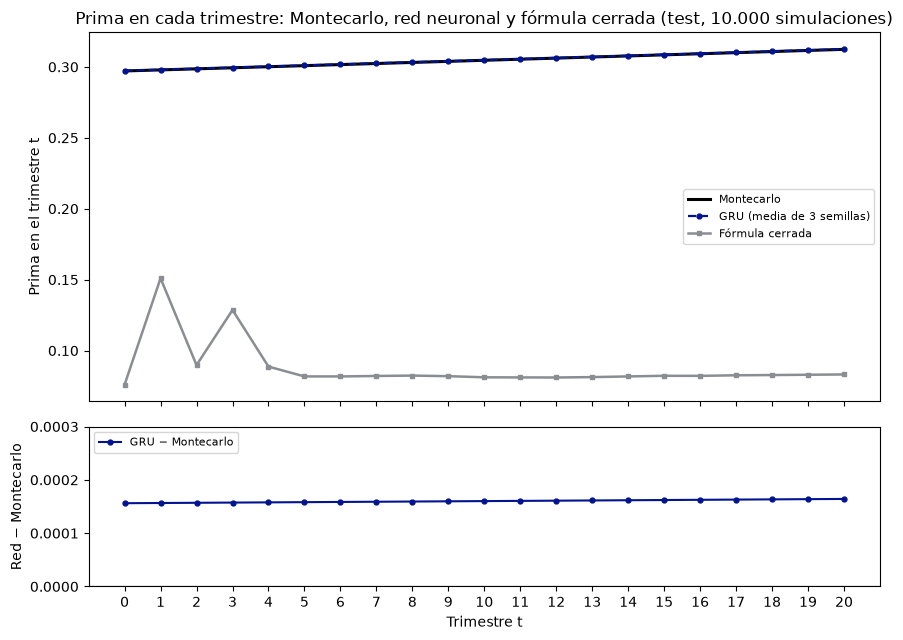

In [12]:
REDES_EN_GRAFICO = ["GRU"]                                 # poner ["GRU", "LSTM"] para ver también la LSTM
COLOR_RED = {"GRU": AZUL, "LSTM": ROJO}

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 6.5), sharex=True, gridspec_kw={"height_ratios": [3, 1.3]})
ax1.plot(ks, mc_k, color="black", lw=2.2, label="Montecarlo")
for t in REDES_EN_GRAFICO:
    ax1.plot(ks, red_k[t], color=COLOR_RED[t], lw=1.6, ls="--", marker="o", ms=3.5, label=f"{t} (media de 3 semillas)")
    ax2.plot(ks, red_k[t] - mc_k, color=COLOR_RED[t], marker="o", ms=3.5, label=f"{t} − Montecarlo")
ax1.plot(ks, bbva_k, color=GRIS, lw=1.8, marker="s", ms=3.5, label="Fórmula cerrada")
ax1.set(ylabel="Prima en el trimestre t", title="Prima en cada trimestre: Montecarlo, red neuronal y fórmula cerrada (test, 10.000 simulaciones)")
ax1.legend(fontsize=8, loc="center right")

ax2.axhline(0, color="black", lw=0.8)
ax2.set(xlabel="Trimestre t", ylabel="Red − Montecarlo", ylim=(0, 0.0003))   # el error (≈0,00016) se lee sobre la propia línea
ax2.set_xticks(ks); ax2.legend(fontsize=8, loc="upper left")
plt.tight_layout(); plt.show()

**Cómo leer el gráfico.** Arriba está la prima en cada trimestre: Montecarlo (negro), GRU (azul, media de 3 semillas) y fórmula cerrada (gris). Montecarlo y GRU suben juntos porque solo cambia el descuento, y casi se tapan. Abajo está su diferencia (GRU − Montecarlo), que ronda 0,00016 en todos los trimestres. La fórmula cerrada queda por debajo y salta en los primeros trimestres, porque en ellos valora siempre la misma trayectoria.


In [13]:
tabla_k.round(5)       # tabla completa, de t = 0 a t = 20

,Montecarlo,LSTM,GRU,LSTM dif. %,GRU dif. %,Fórmula cerrada
t,,,,,,
0,0.29714,0.29754,0.29729,0.13518,0.05258,0.07598
1,0.29788,0.29828,0.29804,0.13518,0.05258,0.15097
2,0.29863,0.29903,0.29878,0.13518,0.05258,0.08975
3,0.29937,0.29978,0.29953,0.13518,0.05258,0.12862
4,0.30012,0.30053,0.30028,0.13518,0.05258,0.08871
5,0.30087,0.30128,0.30103,0.13518,0.05258,0.08178
6,0.30163,0.30204,0.30179,0.13518,0.05258,0.08177
7,0.30238,0.30279,0.30254,0.13518,0.05258,0.08210
8,0.30314,0.30355,0.30330,0.13518,0.05258,0.08237


# 5. Conclusiones

- **Las dos redes aprenden bien el payoff de T20.** En test, el MAE (media de 3 semillas) es 0,00080 en la GRU y 0,00172 en la LSTM, sobre payoffs que llegan a 3. La GRU es más precisa y más estable entre semillas (desviación 0,00001 frente a 0,00038).
- **La prima en t0 de las redes coincide con la del Montecarlo de test.** Sobre las 10.000 trayectorias de test: Montecarlo 0,29714, LSTM 0,29754 (+0,135 %) y GRU 0,29729 (+0,053 %). Con las 100.000 simulaciones, el Montecarlo da 0,3014 ± 0,0029.
- **En los demás trimestres el error relativo es el mismo.** Red y Montecarlo solo se diferencian en el descuento, así que la prima sube de 0,29714 en t0 a 0,31237 en t20 (Montecarlo) y de 0,29729 a 0,31254 (GRU) con la misma diferencia relativa.
- **La fórmula cerrada calcula el payoff de manera diferente.** Usa una sola media geométrica de los 60 precios y da unas 3,9 veces menos que el Montecarlo de test en t0, y entre 3,7 y 3,8 veces menos desde t5. En t1 a t4 salta porque los cinco primeros trimestres son comunes a todas las simulaciones.
- **Con la trayectoria completa la red no ahorra tiempo.** Valorar 10.000 trayectorias ya simuladas tarda 0,08 s (LSTM) y 0,29 s (GRU), frente a 0,007 s del cálculo directo del payoff a partir de esas mismas trayectorias (tiempos de la última ejecución, que cambian en cada una).
- **Límite.** El test sale de la misma simulación que el train (mismo generador, mismos parámetros y mismo comienzo común), así que estos resultados no dicen qué pasaría con otras acciones u otros parámetros.
